# Results

Runs the experiment scripts of this folder and shows their figures.
Each script can also be run on its own from the repo root, e.g. `python experiments/compare_cfr.py`.
Figures are saved in `figures/`. Running everything takes a few minutes.

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, Markdown, display

# works whether the notebook is started from experiments/ or from the repo root
EXP = Path.cwd() if (Path.cwd() / "compare_cfr.py").exists() else Path.cwd() / "experiments"
FIGURES = EXP.parent / "figures"
sys.path.insert(0, str(EXP))

import convergence, compare_cfr

## 1. Regret matching on rock-paper-scissors, CFR on Kuhn poker

Left: in self-play the average strategy goes to (1/3, 1/3, 1/3), even when player 0 starts biased towards rock.
Right: the value of the average strategies of chance sampling CFR goes to the theoretical -1/18.

saved figures\convergence.png


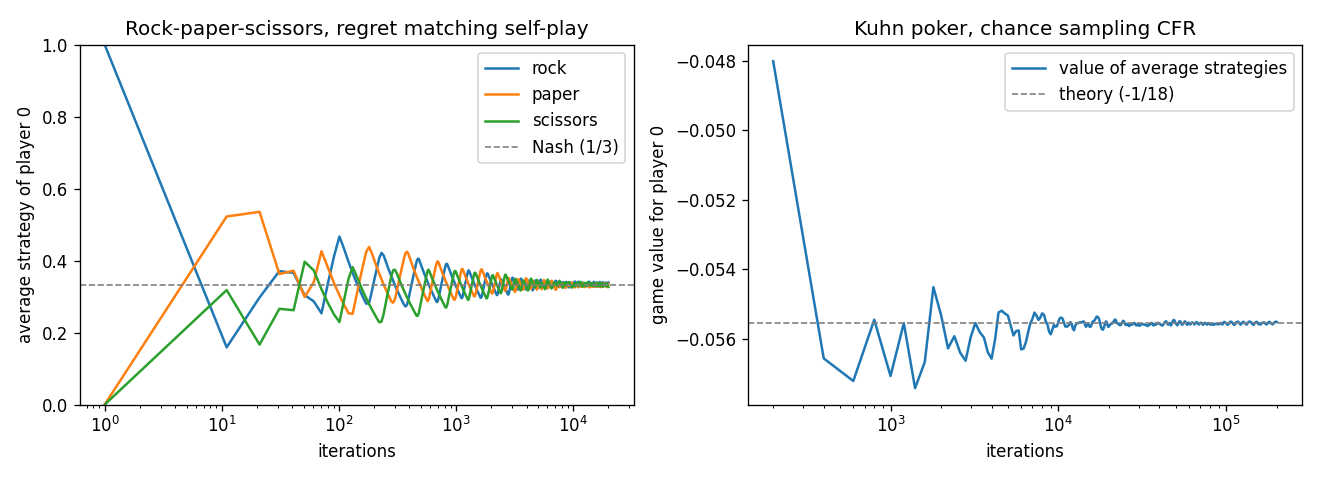

In [2]:
convergence.main()
display(Image(filename=FIGURES / "convergence.png"))

## 2. Vanilla CFR vs chance sampling CFR

Both are measured with the exploitability of their average strategy (0 at a Nash equilibrium),
for the same budget of deals traversed. Chance sampling runs on 3 seeds (median and min-max band).

vanilla CFR ...
chance sampling CFR, seed 0 ...
chance sampling CFR, seed 1 ...
chance sampling CFR, seed 2 ...

   deals | vanilla expl  CS expl (median) | vanilla value  CS value | vanilla s    CS s
       6 |      0.33333           0.40278 |      -0.02083   0.08681 |      0.00    0.00
      30 |      0.15147           0.18181 |      -0.04652  -0.08464 |      0.01    0.02
     126 |      0.05502           0.04553 |      -0.04355  -0.04475 |      0.03    0.05
     504 |      0.03000           0.03673 |      -0.05414  -0.05236 |      0.12    0.20
    1992 |      0.01141           0.01592 |      -0.05457  -0.05392 |      0.47    0.83
    7806 |      0.00648           0.01234 |      -0.05555  -0.05526 |      1.94    3.02
   30612 |      0.00355           0.00439 |      -0.05548  -0.05551 |      7.66   11.72
  120000 |      0.00161           0.00235 |      -0.05556  -0.05554 |     29.90   47.98
theory: exploitability 0, value -0.05556
saved figures/cfr_comparison.png

alpha (learned P(bet

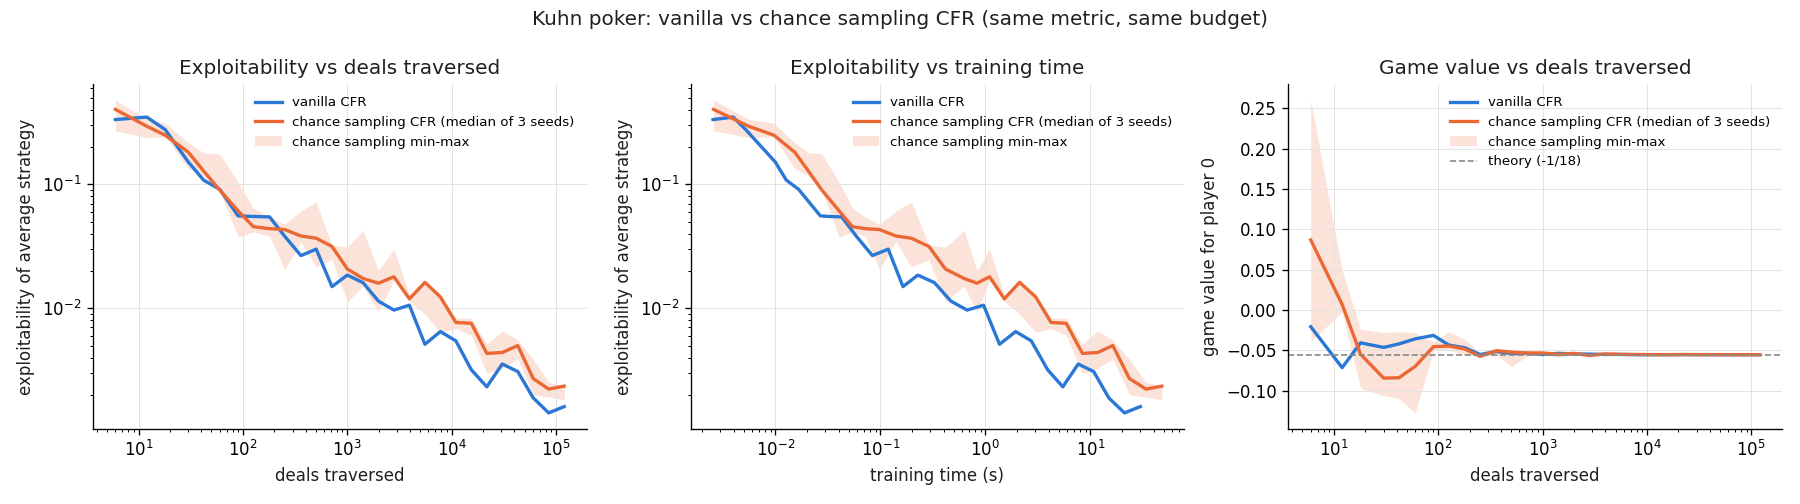

In [3]:
compare_cfr.main([])
display(Image(filename=FIGURES / "cfr_comparison.png"))

## 3. Strategy learned by vanilla CFR vs the known equilibrium

Kuhn has a family of equilibria indexed by alpha in [0, 1/3], so the theoretical column uses the learned alpha.

In [4]:
display(Markdown((FIGURES / "kuhn_strategy.md").read_text(encoding="utf-8")))

alpha (learned P(bet) at "0") = 0.2211

| situation | card | learned P(bet) | theoretical P(bet) |
|---|---|---|---|
| player 0, first move | queen | 0.2211 | 0.2211 |
| player 0, first move | king | 0.0001 | 0.0000 |
| player 0, first move | ace | 0.6605 | 0.6634 |
| player 1, after a check | queen | 0.3325 | 0.3333 |
| player 1, after a check | king | 0.0001 | 0.0000 |
| player 1, after a check | ace | 1.0000 | 1.0000 |
| player 1, facing a bet | queen | 0.0000 | 0.0000 |
| player 1, facing a bet | king | 0.3411 | 0.3333 |
| player 1, facing a bet | ace | 1.0000 | 1.0000 |
| player 0, facing a bet | queen | 0.0000 | 0.0000 |
| player 0, facing a bet | king | 0.5613 | 0.5545 |
| player 0, facing a bet | ace | 1.0000 | 1.0000 |
